In [1]:
# =============================================================================
# CS-781 Phase 1 — Architecture #1: Custom Decoder-only "LLaMA-style" LM
# RMSNorm + Rotary Positional Embeddings (RoPE) + SwiGLU FFN + causal self-attn
# Tokenizer: FROM-SCRATCH byte-level BPE (same algorithm as Assignment 1 —
# byte-level symbols, word-boundary marker, deterministic lexicographic
# tie-breaking, reserved tokens <pad>,<unk>,<s>,</s> in that order).
# Run in Kaggle: paste each "# %%" block as its own cell, or run as one script.
# =============================================================================

# %% [1] Imports & HF login
import os, json, math, random, time, zipfile
from collections import Counter, defaultdict

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from kaggle_secrets import UserSecretsClient
from huggingface_hub import login, hf_hub_download

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)
print("HF login OK")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


HF login OK
Device: cuda


In [3]:
# %% [2] Config
SEED = 42
random.seed(SEED); torch.manual_seed(SEED)

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_FILES = [
    "Phase_1_Pretraining/Train/train_acts.json",
    "Phase_1_Pretraining/Train/train_high_courts.json",
    "Phase_1_Pretraining/Train/train_supreme_court.json",
    "Phase_1_Pretraining/Train/train_tribunals.json",
]
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

TOKENS_PER_SOURCE = 15_000_000      # ~60M train tokens total across 4 sources
VAL_FRACTION = 0.02

BLOCK_SIZE = 1024
BPE_VOCAB_SIZE = 32000              # includes the 4 reserved tokens
N_LAYER = 12
N_HEAD = 12
N_EMBD = 576                        # -> ~110M params
FFN_MULT = 8 / 3
DROPOUT = 0.0

BATCH_SIZE = 8
GRAD_ACCUM = 4
LR = 3e-4
MIN_LR = 3e-5
WARMUP_STEPS = 300
MAX_STEPS = 6000
EVAL_EVERY = 500
LOG_EVERY = 50

TARGET_GEN_WORDS = 128
MAX_GEN_TOKENS = 384
TEMPERATURE = 0.8
TOP_P = 0.95

OUTPUT_DIR = "/kaggle/working/cs781_phase1_arch1"
os.makedirs(OUTPUT_DIR, exist_ok=True)
BPE_SAVE_PATH = os.path.join(OUTPUT_DIR, "legal_bpe.json")
CKPT_PATH = os.path.join(OUTPUT_DIR, "model.pt")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission_phase1_arch1.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "loss.png")

In [4]:
# %% [3] Download raw text from all four sources -> build mixed corpus text list
# FIXED: stream-parse each JSON file record-by-record instead of json.load()-ing
# the whole file into memory. train_high_courts.json (10.7GB) and
# train_tribunals.json (6.5GB) will OOM-kill the kernel with a full json.load().

get_ipython().system('pip install -q ijson')

import ijson

os.makedirs(os.path.join(OUTPUT_DIR, "raw_text"), exist_ok=True)

def stream_records(record_path):
    """Yields one record's dict at a time without loading the whole file."""
    with open(record_path, "rb") as f:
        # Adjust "item" if the JSON isn't a flat top-level array of objects —
        # e.g. use "item.text" style prefixes if it's nested. A flat list
        # (the documented structure for these files) uses "item".
        for record in ijson.items(f, "item"):
            yield record

print("Downloading sources...")
local_paths = {}
for train_file in TRAIN_FILES:
    local_paths[train_file] = hf_hub_download(
        repo_id=HF_DATASET_REPO, filename=train_file,
        repo_type="dataset", token=HF_TOKEN
    )
    print("  downloaded:", train_file)

# Build a bounded corpus (list of raw text strings) for BPE training,
# capped per-source by characters (~5 chars/token heuristic).
# Streaming means we stop reading the file as soon as the cap is hit —
# we never hold the full multi-GB file in memory.
bpe_train_texts = []
for train_file, path in local_paths.items():
    char_cap = TOKENS_PER_SOURCE * 5
    n_chars = 0
    for r in stream_records(path):
        t = r["text"]
        bpe_train_texts.append(t)
        n_chars += len(t)
        if n_chars >= char_cap:
            break
    print(f"  {train_file}: ~{n_chars:,} chars queued")

import gc
gc.collect()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.8/149.8 kB 3.4 MB/s eta 0:00:00a 0:00:01


Phase_1_Pretraining/Train/train_acts.jso(…):   0%|          | 0.00/729M [00:00<?, ?B/s]

  downloaded: Phase_1_Pretraining/Train/train_acts.json


Phase_1_Pretraining/Train/train_high_cou(…):   0%|          | 0.00/10.7G [00:00<?, ?B/s]

  downloaded: Phase_1_Pretraining/Train/train_high_courts.json


Phase_1_Pretraining/Train/train_supreme_(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

  downloaded: Phase_1_Pretraining/Train/train_supreme_court.json


Phase_1_Pretraining/Train/train_tribunal(…):   0%|          | 0.00/6.48G [00:00<?, ?B/s]

  downloaded: Phase_1_Pretraining/Train/train_tribunals.json
  Phase_1_Pretraining/Train/train_acts.json: ~75,008,526 chars queued
  Phase_1_Pretraining/Train/train_high_courts.json: ~75,001,545 chars queued
  Phase_1_Pretraining/Train/train_supreme_court.json: ~75,008,561 chars queued
  Phase_1_Pretraining/Train/train_tribunals.json: ~75,093,704 chars queued


202

In [5]:
# %% [4] Train a from-scratch byte-level BPE tokenizer (A1-style algorithm)
RESERVED_TOKENS = ["<pad>", "<unk>", "<s>", "</s>"]
EOW = "\u0100"   # single-char end-of-word marker, outside the 0-255 byte range
                 # (avoids ambiguity with real byte values during decode)

def word_to_symbols(word):
    # byte-level: each UTF-8 byte -> one Latin-1 char (codepoint 0-255),
    # then the sentinel end-of-word char is appended.
    return tuple(chr(b) for b in word.encode("utf-8", "ignore")) + (EOW,)

def get_word_freqs(texts):
    freqs = Counter()
    for t in texts:
        for w in t.split():
            freqs[w] += 1
    return freqs

def train_bpe(word_freqs, vocab_size, reserved=RESERVED_TOKENS):
    """
    Standard iterative BPE merge, with the required deterministic
    tie-breaking rule: among pairs tied for max frequency, pick the
    lexicographically smallest pair. Uses incremental pair-count updates
    (only revisits words containing the merged pair) so it stays tractable
    on a multi-million-token corpus.
    """
    corpus = {}
    for w, f in word_freqs.items():
        symbols = word_to_symbols(w)
        corpus[symbols] = corpus.get(symbols, 0) + f

    vocab_set = set()
    for symbols in corpus:
        vocab_set.update(symbols)
    vocab = list(reserved) + sorted(vocab_set)
    merges = []

    def get_pair_stats(corpus):
        pair_freqs = Counter()
        pair_words = defaultdict(set)
        for symbols, freq in corpus.items():
            for i in range(len(symbols) - 1):
                pair = (symbols[i], symbols[i + 1])
                pair_freqs[pair] += freq
                pair_words[pair].add(symbols)
        return pair_freqs, pair_words

    pair_freqs, pair_words = get_pair_stats(corpus)

    while len(vocab) < vocab_size and pair_freqs:
        max_freq = max(pair_freqs.values())
        if max_freq <= 1:
            break
        best_candidates = [p for p, c in pair_freqs.items() if c == max_freq]
        best_pair = min(best_candidates)   # deterministic: lexicographically smallest
        merges.append(best_pair)
        new_symbol = best_pair[0] + best_pair[1]
        vocab.append(new_symbol)

        affected = list(pair_words[best_pair])
        for symbols in affected:
            freq = corpus.pop(symbols)
            for i in range(len(symbols) - 1):
                p = (symbols[i], symbols[i + 1])
                pair_freqs[p] -= freq
                if pair_freqs[p] <= 0:
                    pair_freqs.pop(p, None)
                pair_words[p].discard(symbols)

            new_symbols, i = [], 0
            while i < len(symbols):
                if i < len(symbols) - 1 and symbols[i] == best_pair[0] and symbols[i + 1] == best_pair[1]:
                    new_symbols.append(new_symbol)
                    i += 2
                else:
                    new_symbols.append(symbols[i])
                    i += 1
            new_symbols = tuple(new_symbols)
            corpus[new_symbols] = corpus.get(new_symbols, 0) + freq

            for i in range(len(new_symbols) - 1):
                p = (new_symbols[i], new_symbols[i + 1])
                pair_freqs[p] += freq
                pair_words[p].add(new_symbols)

        pair_freqs.pop(best_pair, None)
        pair_words.pop(best_pair, None)

        if len(merges) % 1000 == 0:
            print(f"  BPE merges learned: {len(merges)} | vocab size: {len(vocab)}")

    return vocab, merges

print("Building word-frequency table for BPE training...")
word_freqs = get_word_freqs(bpe_train_texts)
print("Unique words:", len(word_freqs))

print("Training byte-level BPE (this may take a while)...")
t0 = time.time()
vocab, merges = train_bpe(word_freqs, BPE_VOCAB_SIZE, RESERVED_TOKENS)
print(f"BPE training done in {(time.time()-t0)/60:.1f} min. Final vocab size: {len(vocab)}")

with open(BPE_SAVE_PATH, "w", encoding="utf-8") as f:
    json.dump({"merges": [list(p) for p in merges], "itos": vocab,
               "vocab_size": len(vocab)}, f, ensure_ascii=False)
print("Saved tokenizer:", BPE_SAVE_PATH)

Building word-frequency table for BPE training...
Unique words: 708409
Training byte-level BPE (this may take a while)...
  BPE merges learned: 1000 | vocab size: 1181
  BPE merges learned: 2000 | vocab size: 2181
  BPE merges learned: 3000 | vocab size: 3181
  BPE merges learned: 4000 | vocab size: 4181
  BPE merges learned: 5000 | vocab size: 5181
  BPE merges learned: 6000 | vocab size: 6181
  BPE merges learned: 7000 | vocab size: 7181
  BPE merges learned: 8000 | vocab size: 8181
  BPE merges learned: 9000 | vocab size: 9181
  BPE merges learned: 10000 | vocab size: 10181
  BPE merges learned: 11000 | vocab size: 11181
  BPE merges learned: 12000 | vocab size: 12181
  BPE merges learned: 13000 | vocab size: 13181
  BPE merges learned: 14000 | vocab size: 14181
  BPE merges learned: 15000 | vocab size: 15181
  BPE merges learned: 16000 | vocab size: 16181
  BPE merges learned: 17000 | vocab size: 17181
  BPE merges learned: 18000 | vocab size: 18181
  BPE merges learned: 19000 | vo

In [6]:
# %% [5] Tokenizer encode/decode built on the learned merges
token_to_id = {tok: i for i, tok in enumerate(vocab)}
merges_rank = {p: i for i, p in enumerate(merges)}
PAD_ID = token_to_id["<pad>"]
UNK_ID = token_to_id["<unk>"]
BOS_ID = token_to_id["<s>"]
EOS_ID = token_to_id["</s>"]
ACTUAL_VOCAB_SIZE = len(vocab)

def bpe_encode_word(word):
    symbols = list(word_to_symbols(word))
    while len(symbols) > 1:
        pairs = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
        ranked = [(merges_rank[p], p) for p in pairs if p in merges_rank]
        if not ranked:
            break
        _, best = min(ranked)
        new_symbols, i = [], 0
        while i < len(symbols):
            if i < len(symbols) - 1 and symbols[i] == best[0] and symbols[i + 1] == best[1]:
                new_symbols.append(best[0] + best[1])
                i += 2
            else:
                new_symbols.append(symbols[i])
                i += 1
        symbols = new_symbols
    return symbols

def encode(text, add_bos=True, add_eos=True):
    ids = [BOS_ID] if add_bos else []
    for w in text.split():
        for sym in bpe_encode_word(w):
            ids.append(token_to_id.get(sym, UNK_ID))
    if add_eos:
        ids.append(EOS_ID)
    return ids

def decode(ids):
    byte_buf = []
    for i in ids:
        if i in (PAD_ID, BOS_ID, EOS_ID):
            continue
        if i == UNK_ID:
            continue
        tok = vocab[i]
        for ch in tok:
            if ch == EOW:
                byte_buf.append(0x20)  # word boundary -> space
            elif ord(ch) <= 255:
                byte_buf.append(ord(ch))
    text = bytes(byte_buf).decode("utf-8", errors="replace")
    return text.strip()

print("Tokenizer ready. Vocab size:", ACTUAL_VOCAB_SIZE)
print("Sanity check:", decode(encode("The petitioner filed the present appeal.")))

Tokenizer ready. Vocab size: 32000
Sanity check: The petitioner filed the present appeal.


In [9]:
# %% [6] Tokenize corpus into train/val token streams (per-source, then combined)
# FIXED: use stream_records() (from cell 3) instead of the old load_records(),
# so we never json.load() a whole multi-GB file into memory here either.

train_tokens, val_tokens = [], []
random.seed(SEED)
for train_file, path in local_paths.items():
    src_train, src_val = [], []
    for r in stream_records(path):
        ids = encode(r["text"], add_bos=True, add_eos=True)
        if random.random() < VAL_FRACTION:
            src_val.extend(ids)
        else:
            src_train.extend(ids)
        if len(src_train) >= TOKENS_PER_SOURCE:
            break
    train_tokens.extend(src_train[:TOKENS_PER_SOURCE])
    val_tokens.extend(src_val[: int(TOKENS_PER_SOURCE * VAL_FRACTION)])
    print(f"{train_file}: train={len(src_train):,} val={len(src_val):,}")

print(f"TOTAL train tokens: {len(train_tokens):,} | val tokens: {len(val_tokens):,}")

def make_blocks(tokens, block_size):
    n = (len(tokens) // block_size) * block_size
    tokens = tokens[:n]
    return torch.tensor(tokens, dtype=torch.long).view(-1, block_size)

train_blocks = make_blocks(train_tokens, BLOCK_SIZE)
val_blocks = make_blocks(val_tokens, BLOCK_SIZE)
print("Train blocks:", train_blocks.shape, "Val blocks:", val_blocks.shape)

class BlockDataset(Dataset):
    def __init__(self, blocks):
        self.blocks = blocks
    def __len__(self):
        return self.blocks.size(0)
    def __getitem__(self, idx):
        x = self.blocks[idx][:-1]
        y = self.blocks[idx][1:]
        return x, y

train_ds = BlockDataset(train_blocks)
val_ds = BlockDataset(val_blocks)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=True)

Phase_1_Pretraining/Train/train_acts.json: train=15,002,792 val=241,589
Phase_1_Pretraining/Train/train_high_courts.json: train=15,000,414 val=321,408
Phase_1_Pretraining/Train/train_supreme_court.json: train=15,002,208 val=334,735
Phase_1_Pretraining/Train/train_tribunals.json: train=15,007,197 val=224,923
TOTAL train tokens: 60,000,000 | val tokens: 1,066,512
Train blocks: torch.Size([58593, 1024]) Val blocks: torch.Size([1041, 1024])


In [10]:
# %% [7] Model: RMSNorm + RoPE + SwiGLU decoder-only Transformer (from scratch)
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        norm = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        return norm * self.weight

def build_rope_cache(seq_len, head_dim, device, base=10000.0):
    inv_freq = 1.0 / (base ** (torch.arange(0, head_dim, 2, device=device).float() / head_dim))
    t = torch.arange(seq_len, device=device).float()
    freqs = torch.einsum("i,j->ij", t, inv_freq)
    emb = torch.cat((freqs, freqs), dim=-1)
    return emb.cos()[None, None, :, :], emb.sin()[None, None, :, :]

def rotate_half(x):
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat((-x2, x1), dim=-1)

def apply_rope(q, k, cos, sin):
    q = (q * cos) + (rotate_half(q) * sin)
    k = (k * cos) + (rotate_half(k) * sin)
    return q, k

class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, dropout):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.head_dim = n_embd // n_head
        self.qkv = nn.Linear(n_embd, 3 * n_embd, bias=False)
        self.proj = nn.Linear(n_embd, n_embd, bias=False)
        self.dropout = dropout

    def forward(self, x, cos, sin):
        B, T, C = x.shape
        qkv = self.qkv(x).view(B, T, 3, self.n_head, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        q, k = apply_rope(q, k, cos[:, :, :T, :], sin[:, :, :T, :])
        out = F.scaled_dot_product_attention(
            q, k, v, is_causal=True,
            dropout_p=self.dropout if self.training else 0.0
        )
        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.proj(out)

class SwiGLU(nn.Module):
    def __init__(self, n_embd, mult, dropout):
        super().__init__()
        hidden = int(mult * n_embd)
        hidden = ((hidden + 63) // 64) * 64
        self.w1 = nn.Linear(n_embd, hidden, bias=False)
        self.w2 = nn.Linear(n_embd, hidden, bias=False)
        self.w3 = nn.Linear(hidden, n_embd, bias=False)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.drop(self.w3(F.silu(self.w1(x)) * self.w2(x)))

class Block(nn.Module):
    def __init__(self, n_embd, n_head, ffn_mult, dropout):
        super().__init__()
        self.ln1 = RMSNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, dropout)
        self.ln2 = RMSNorm(n_embd)
        self.ffn = SwiGLU(n_embd, ffn_mult, dropout)
    def forward(self, x, cos, sin):
        x = x + self.attn(self.ln1(x), cos, sin)
        x = x + self.ffn(self.ln2(x))
        return x

class LegalLLaMA(nn.Module):
    def __init__(self, vocab_size, n_layer, n_head, n_embd, block_size, ffn_mult, dropout):
        super().__init__()
        self.block_size = block_size
        self.head_dim = n_embd // n_head
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([Block(n_embd, n_head, ffn_mult, dropout) for _ in range(n_layer)])
        self.ln_f = RMSNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size, bias=False)
        self.tok_emb.weight = self.head.weight
        cos, sin = build_rope_cache(block_size, self.head_dim, device="cpu")
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.drop(self.tok_emb(idx))
        cos = self.rope_cos.to(idx.device)
        sin = self.rope_sin.to(idx.device)
        for blk in self.blocks:
            x = blk(x, cos, sin)
        x = self.ln_f(x)
        logits = self.head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_p=0.95, eos_id=None):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-5)
            probs = F.softmax(logits, dim=-1)
            sorted_probs, sorted_idx = torch.sort(probs, descending=True, dim=-1)
            cum_probs = torch.cumsum(sorted_probs, dim=-1)
            cutoff = (cum_probs > top_p)
            cutoff[:, 1:] = cutoff[:, :-1].clone()
            cutoff[:, 0] = False
            sorted_probs[cutoff] = 0.0
            sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
            next_sorted = torch.multinomial(sorted_probs, num_samples=1)
            next_id = sorted_idx.gather(-1, next_sorted)
            idx = torch.cat([idx, next_id], dim=1)
            if eos_id is not None and (next_id == eos_id).all():
                break
        return idx

model = LegalLLaMA(ACTUAL_VOCAB_SIZE, N_LAYER, N_HEAD, N_EMBD, BLOCK_SIZE, FFN_MULT, DROPOUT).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model size: {n_params/1e6:.2f}M parameters")
assert 50e6 <= n_params <= 300e6, "Model must be 50M-300M params — adjust N_LAYER/N_EMBD"

Model size: 66.22M parameters


In [11]:

# %% [8] Training loop (manual — AdamW, cosine LR w/ warmup, grad accumulation, AMP)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.1)
scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

def lr_at(step):
    if step < WARMUP_STEPS:
        return LR * step / max(1, WARMUP_STEPS)
    progress = (step - WARMUP_STEPS) / max(1, MAX_STEPS - WARMUP_STEPS)
    progress = min(progress, 1.0)
    return MIN_LR + 0.5 * (LR - MIN_LR) * (1 + math.cos(math.pi * progress))

@torch.no_grad()
def evaluate():
    model.eval()
    losses = []
    for i, (x, y) in enumerate(val_loader):
        if i >= 50:
            break
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=torch.cuda.is_available()):
            _, loss = model(x, y)
        losses.append(loss.item())
    model.train()
    return sum(losses) / max(1, len(losses))

history = {"step": [], "train_loss": [], "eval_step": [], "eval_loss": []}
step = 0
t0 = time.time()
model.train()
data_iter = iter(train_loader)

while step < MAX_STEPS:
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0
    for _ in range(GRAD_ACCUM):
        try:
            x, y = next(data_iter)
        except StopIteration:
            data_iter = iter(train_loader)
            x, y = next(data_iter)
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=torch.cuda.is_available()):
            _, loss = model(x, y)
            loss = loss / GRAD_ACCUM
        scaler.scale(loss).backward()
        accum_loss += loss.item()

    lr = lr_at(step)
    for g in optimizer.param_groups:
        g["lr"] = lr
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(optimizer)
    scaler.update()

    if step % LOG_EVERY == 0:
        elapsed = time.time() - t0
        print(f"step {step:5d} | loss {accum_loss:.4f} | lr {lr:.2e} | elapsed {elapsed/60:.1f}m")
        history["step"].append(step)
        history["train_loss"].append(accum_loss)

    if step % EVAL_EVERY == 0 and step > 0:
        val_loss = evaluate()
        ppl = math.exp(val_loss)
        print(f"  [eval] step {step} | val_loss {val_loss:.4f} | perplexity {ppl:.2f}")
        history["eval_step"].append(step)
        history["eval_loss"].append(val_loss)

    step += 1

final_val_loss = evaluate()
final_ppl = math.exp(final_val_loss)
print(f"FINAL val loss: {final_val_loss:.4f} | perplexity: {final_ppl:.4f}")

/tmp/ipykernel_58/3515687552.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())


step     0 | loss 10.5382 | lr 0.00e+00 | elapsed 0.0m
step    50 | loss 8.7997 | lr 5.00e-05 | elapsed 1.5m
step   100 | loss 7.5091 | lr 1.00e-04 | elapsed 3.1m
step   150 | loss 6.7596 | lr 1.50e-04 | elapsed 4.7m
step   200 | loss 6.2861 | lr 2.00e-04 | elapsed 6.3m
step   250 | loss 6.0658 | lr 2.50e-04 | elapsed 8.0m
step   300 | loss 5.5260 | lr 3.00e-04 | elapsed 9.6m
step   350 | loss 5.3358 | lr 3.00e-04 | elapsed 11.2m
step   400 | loss 4.6245 | lr 3.00e-04 | elapsed 12.9m
step   450 | loss 4.3351 | lr 3.00e-04 | elapsed 14.5m
step   500 | loss 4.5745 | lr 2.99e-04 | elapsed 16.1m
  [eval] step 500 | val_loss 4.1845 | perplexity 65.66
step   550 | loss 4.4906 | lr 2.99e-04 | elapsed 17.9m
step   600 | loss 4.0548 | lr 2.98e-04 | elapsed 19.6m
step   650 | loss 4.0050 | lr 2.97e-04 | elapsed 21.2m
step   700 | loss 4.0418 | lr 2.97e-04 | elapsed 22.8m
step   750 | loss 4.3890 | lr 2.96e-04 | elapsed 24.5m
step   800 | loss 4.0223 | lr 2.95e-04 | elapsed 26.1m
step   850 | los

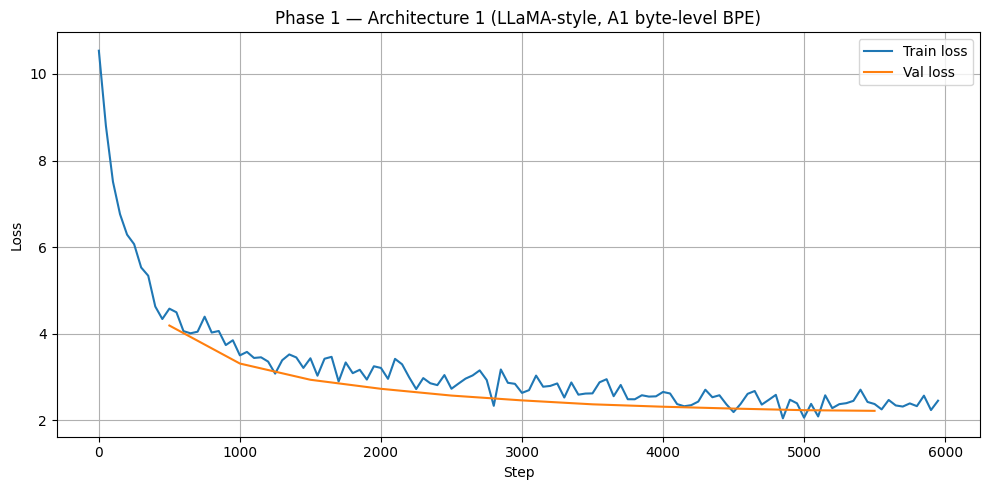

Saved loss plot: /kaggle/working/cs781_phase1_arch1/loss.png


In [12]:
# %% [9] Plot loss curv
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(history["step"], history["train_loss"], label="Train loss")
plt.plot(history["eval_step"], history["eval_loss"], label="Val loss")
plt.xlabel("Step"); plt.ylabel("Loss")
plt.title("Phase 1 — Architecture 1 (LLaMA-style, A1 byte-level BPE)")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()
print("Saved loss plot:", LOSS_PLOT_PATH)

In [13]:

# %% [10] Save checkpoint
torch.save({
    "model_state_dict": model.state_dict(),
    "config": dict(vocab_size=ACTUAL_VOCAB_SIZE, n_layer=N_LAYER, n_head=N_HEAD,
                   n_embd=N_EMBD, block_size=BLOCK_SIZE, ffn_mult=FFN_MULT, dropout=DROPOUT),
}, CKPT_PATH)
print("Saved checkpoint:", CKPT_PATH)

Saved checkpoint: /kaggle/working/cs781_phase1_arch1/model.pt


In [14]:
# %% [11] Load test prompts & generate 128-word continuations
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO, filename=TEST_FILE, repo_type="dataset", token=HF_TOKEN
)
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print("Test examples:", len(test_data))

model.eval()
predictions = {}
MAX_PROMPT_TOKENS = BLOCK_SIZE - MAX_GEN_TOKENS

for i, (example_id, record) in enumerate(test_data.items()):
    prompt_ids = encode(record["text"], add_bos=True, add_eos=False)[:MAX_PROMPT_TOKENS]
    idx = torch.tensor([prompt_ids], dtype=torch.long, device=device)
    out = model.generate(idx, max_new_tokens=MAX_GEN_TOKENS,
                          temperature=TEMPERATURE, top_p=TOP_P, eos_id=EOS_ID)
    gen_ids = out[0, len(prompt_ids):].tolist()
    gen_text = decode(gen_ids)
    gen_words = gen_text.split()[:TARGET_GEN_WORDS]
    predictions[str(example_id)] = {"text": " ".join(gen_words)}
    if (i + 1) % 50 == 0:
        print(f"Generated {i+1}/{len(test_data)}")

test.json: 0.00B [00:00, ?B/s]

Test examples: 1000
Generated 50/1000
Generated 100/1000
Generated 150/1000
Generated 200/1000
Generated 250/1000
Generated 300/1000
Generated 350/1000
Generated 400/1000
Generated 450/1000
Generated 500/1000
Generated 550/1000
Generated 600/1000
Generated 650/1000
Generated 700/1000
Generated 750/1000
Generated 800/1000
Generated 850/1000
Generated 900/1000
Generated 950/1000
Generated 1000/1000


In [15]:

# %% [12] Save prediction.json + zip Codabench
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)
print("Saved:", PREDICTION_PATH)

with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(PREDICTION_PATH, arcname="prediction.json")
print("Codabench submission ready:", SUBMISSION_ZIP)

Saved: /kaggle/working/cs781_phase1_arch1/prediction.json
Codabench submission ready: /kaggle/working/cs781_phase1_arch1/submission_phase1_arch1.zip


In [16]:
# %% [PERSIST] Save reusable artifacts so Arch #2/#3/#4 don't redo BPE + tokenization
# Run this ONCE, right after cell [6] finishes successfully (i.e. after
# train_blocks / val_blocks / vocab / merges all exist in memory).
#
# After running this cell, go to: Save Version -> "Save & Run All (Commit)".
# That freezes /kaggle/working/cs781_phase1_artifacts as a Kaggle Output Dataset
# tied to THIS notebook. In your next notebook (Architecture #2, #3, #4),
# click "Add Input" -> search your own notebook's name -> attach it, and its
# files will appear under /kaggle/input/<your-notebook-name>/.

import torch, json, os

ARTIFACT_DIR = "/kaggle/working/cs781_phase1_artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# 1. Tokenizer (vocab + merges) — reuse verbatim across all architectures.
with open(os.path.join(ARTIFACT_DIR, "legal_bpe.json"), "w", encoding="utf-8") as f:
    json.dump({"merges": [list(p) for p in merges], "itos": vocab,
               "vocab_size": len(vocab)}, f, ensure_ascii=False)

# 2. Already-tokenized train/val token ID tensors (raw, un-chunked) —
#    reuse across architectures EVEN IF they use a different BLOCK_SIZE,
#    since chunking into blocks happens after this point.
torch.save(torch.tensor(train_tokens, dtype=torch.long),
           os.path.join(ARTIFACT_DIR, "train_tokens.pt"))
torch.save(torch.tensor(val_tokens, dtype=torch.long),
           os.path.join(ARTIFACT_DIR, "val_tokens.pt"))

print("Saved to:", ARTIFACT_DIR)
print(os.listdir(ARTIFACT_DIR))
print("\nNow: Save Version -> Save & Run All (Commit) to persist this as a Kaggle dataset.")


# =============================================================================
# In your NEXT notebook (Architecture #2/#3/#4), replace cells [3]-[6] with this:
# =============================================================================
"""
import torch, json

ARTIFACT_PATH = "/kaggle/input/<your-committed-notebook-slug>/cs781_phase1_artifacts"

# --- Load tokenizer (identical across all architectures) ---
with open(f"{ARTIFACT_PATH}/legal_bpe.json", "r", encoding="utf-8") as f:
    _tok = json.load(f)
vocab = _tok["itos"]
merges = [tuple(p) for p in _tok["merges"]]
token_to_id = {tok: i for i, tok in enumerate(vocab)}
merges_rank = {p: i for i, p in enumerate(merges)}
PAD_ID = token_to_id["<pad>"]
UNK_ID = token_to_id["<unk>"]
BOS_ID = token_to_id["<s>"]
EOS_ID = token_to_id["</s>"]
ACTUAL_VOCAB_SIZE = len(vocab)
# (keep EOW, word_to_symbols, bpe_encode_word, encode, decode definitions
#  from the original script unchanged — only the vocab/merges are now loaded,
#  not retrained)

# --- Load pre-tokenized corpus (skips re-downloading + re-encoding 4 huge files) ---
train_tokens = torch.load(f"{ARTIFACT_PATH}/train_tokens.pt").tolist()
val_tokens = torch.load(f"{ARTIFACT_PATH}/val_tokens.pt").tolist()

# Then continue straight into make_blocks(...) with THIS architecture's
# own BLOCK_SIZE, model definition, and training loop.
"""

Saved to: /kaggle/working/cs781_phase1_artifacts
['val_tokens.pt', 'legal_bpe.json', 'train_tokens.pt']

Now: Save Version -> Save & Run All (Commit) to persist this as a Kaggle dataset.


'\nimport torch, json\n\nARTIFACT_PATH = "/kaggle/input/<your-committed-notebook-slug>/cs781_phase1_artifacts"\n\n# --- Load tokenizer (identical across all architectures) ---\nwith open(f"{ARTIFACT_PATH}/legal_bpe.json", "r", encoding="utf-8") as f:\n    _tok = json.load(f)\nvocab = _tok["itos"]\nmerges = [tuple(p) for p in _tok["merges"]]\ntoken_to_id = {tok: i for i, tok in enumerate(vocab)}\nmerges_rank = {p: i for i, p in enumerate(merges)}\nPAD_ID = token_to_id["<pad>"]\nUNK_ID = token_to_id["<unk>"]\nBOS_ID = token_to_id["<s>"]\nEOS_ID = token_to_id["</s>"]\nACTUAL_VOCAB_SIZE = len(vocab)\n# (keep EOW, word_to_symbols, bpe_encode_word, encode, decode definitions\n#  from the original script unchanged — only the vocab/merges are now loaded,\n#  not retrained)\n\n# --- Load pre-tokenized corpus (skips re-downloading + re-encoding 4 huge files) ---\ntrain_tokens = torch.load(f"{ARTIFACT_PATH}/train_tokens.pt").tolist()\nval_tokens = torch.load(f"{ARTIFACT_PATH}/val_tokens.pt").toli